[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch05-short_workbook.ipynb)

# Two words in two numbers

A recurrent network reads `the`, then `cat`, and keeps two numbers between
words. What do the two numbers hold after `cat`? How much of a learning
signal from a later word gets back to a word 20 or 50 steps earlier?

In [1]:
#@title Setup: run this cell first
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

# The lecture's two-unit network: the weights on the old state and on the new word.
W_HH = np.array([[0.5, 0.1], [0.2, 0.3]])
W_XH = np.array([[0.4, 0.2], [0.1, 0.3]])
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8})


def fmt(v):  # a state as (0.380, 0.385)
    return "(" + ", ".join(f"{x:.3f}" for x in v) + ")"


def step(h, x):  # one step: the old state times W_HH plus the word times W_XH, then tanh
    return np.tanh(W_HH @ h + W_XH @ np.asarray(x, dtype=float))


def fade(factors, steps):  # the signal left after each step back, one line per factor, log scale
    k = np.arange(steps + 1)
    fig, ax = plt.subplots(figsize=(6, 2.8), layout="constrained")
    for name, f in factors.items():
        print(f"{name}: {f} per step, {f ** steps:.1e} left after {steps} steps")
        ax.plot(k, f ** k, label=name)
    ax.set(yscale="log", xlabel="steps back", ylabel="signal left", title=f"the signal left after each step, {steps} steps")
    ax.legend(fontsize=8)
    plt.show()

## 1. Two steps fold two words into one state

Each step multiplies the old state by `W_HH`, adds the new word multiplied by
`W_XH`, and tanh keeps each number between -1 and 1. The state starts at
`[0, 0]`, `the` is `[1, 0]` and `cat` is `[0, 1]`. Run the cell: what is the
state after `cat`? Then swap `X1` and `X2` and run it again.

In [2]:
X1 = [1, 0]  # the
X2 = [0, 1]  # cat
h1 = step(np.zeros(2), X1)
print("state after the first word: ", fmt(h1))
print("state after the second word:", fmt(step(h1, X2)))

state after the first word:  (0.380, 0.100)
state after the second word: (0.380, 0.385)


### Solution

In [3]:
the_cat = step(step(np.zeros(2), [1, 0]), [0, 1])
cat_the = step(step(np.zeros(2), [0, 1]), [1, 0])
display(Markdown(f"After `the`, `cat` the state is {fmt(the_cat)}; after `cat`, `the` it is {fmt(cat_the)}. "
                 "The second word enters the state directly and the first only through the old state, so two "
                 "numbers hold both words and their order."))

After `the`, `cat` the state is (0.380, 0.385); after `cat`, `the` it is (0.484, 0.223). The second word enters the state directly and the first only through the old state, so two numbers hold both words and their order.

## 2. A learning signal fades step by step

Training sends a signal back from a later word one step at a time, and each
step multiplies it by a factor. In the lecture's two trained networks the
factor is about 0.61 for a plain recurrent network and 0.79 along an LSTM's
cell state. Run the cell: how much is left 20 steps back? Then set `STEPS` to
50 and run it again.

plain RNN: 0.61 per step, 5.1e-05 left after 20 steps
LSTM cell state: 0.79 per step, 9.0e-03 left after 20 steps


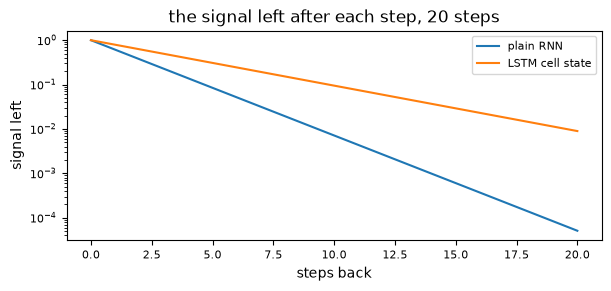

In [4]:
FACTORS = {"plain RNN": 0.61, "LSTM cell state": 0.79}
STEPS = 20
fade(FACTORS, STEPS)

### Solution

In [5]:
rnn20, cell20, rnn50, cell50 = 0.61 ** 20, 0.79 ** 20, 0.61 ** 50, 0.79 ** 50
display(Markdown(f"After 20 steps the plain network keeps {rnn20:.1e} of the signal and the cell state {cell20:.1e}, "
                 f"{cell20 / rnn20:.0f} times more. After 50 steps it is {rnn50:.1e} against {cell50:.1e}, "
                 f"{cell50 / rnn50:,.0f} times more. Both fade; the cell state fades more slowly, and the gap "
                 "between them grows with every step."))

After 20 steps the plain network keeps 5.1e-05 of the signal and the cell state 9.0e-03, 176 times more. After 50 steps it is 1.8e-11 against 7.6e-06, 411,967 times more. Both fade; the cell state fades more slowly, and the gap between them grows with every step.